# BBC News Classification with BERT: Lab
# Solution

## Overview
As a junior data scientist at NewsInsight, a media analytics company, you've been tasked with building an automated news categorization system. Your team needs to classify incoming news articles into appropriate categories to help journalists, researchers, and business analysts quickly find relevant information.

The company receives thousands of articles daily from various sources. Currently, human editors spend significant time manually categorizing these articles, which is time-consuming and inconsistent. Your manager has asked you to develop a machine learning solution that can automatically categorize news articles into predefined categories (business, entertainment, politics, sport, tech).

This project will follow the BERT fine-tuning process you've learned:
1. Understanding data and defining requirements
2. Selecting and preparing the BERT model
3. Data preparation and tokenization
4. Model architecture design
5. Fine-tuning the model
6. Evaluation and refinement

Successfully implementing this system will significantly improve workflow efficiency, allowing editors to focus on content quality rather than manual categorization.

## Part 1: Environment Setup and Data Loading

In [8]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random
import os
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, ConfusionMatrixDisplay
import seaborn as sns

# Set random seeds for reproducibility
def set_seed(seed_value=42):
    random.seed(seed_value)
    np.random.seed(seed_value)
    os.environ['PYTHONHASHSEED'] = str(seed_value)

set_seed()

In [9]:
# Load the data from csv file
df = pd.read_csv('bbc_news_data.csv', sep='\t')
df.head()

,category,filename,title,content
0,business,001.txt,Ad sales boost Time Warner profit,Quarterly profits at US media giant TimeWarne...
1,business,002.txt,Dollar gains on Greenspan speech,The dollar has hit its highest level against ...
2,business,003.txt,Yukos unit buyer faces loan claim,The owners of embattled Russian oil giant Yuk...
3,business,004.txt,High fuel prices hit BA's profits,British Airways has blamed high fuel prices f...
4,business,005.txt,Pernod takeover talk lifts Domecq,Shares in UK drinks and food firm Allied Dome...


<!-- ## Part 2: Data Exploration and Preprocessing -->

Explore the dataset, displaying basic information and:
- Analyze category distribution
- Check text length distribution
- Train test split data, use 75-25 split

In [10]:
# ### scrach pad

# # df['category'].unique()
# # Category distribution
# category_counts = df['category'].value_counts() # None
# category_counts

# # Visualize category distribution
# category_counts.plot(kind='bar')
# plt.xlabel('Category')
# plt.ylabel('Number of Articles')
# plt.title('BBC News Category Distribution')
# plt.xticks(rotation=45)
# plt.tight_layout()
# plt.show()
# # None

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2225 entries, 0 to 2224
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   category  2225 non-null   object
 1   filename  2225 non-null   object
 2   title     2225 non-null   object
 3   content   2225 non-null   object
dtypes: object(4)
memory usage: 69.7+ KB


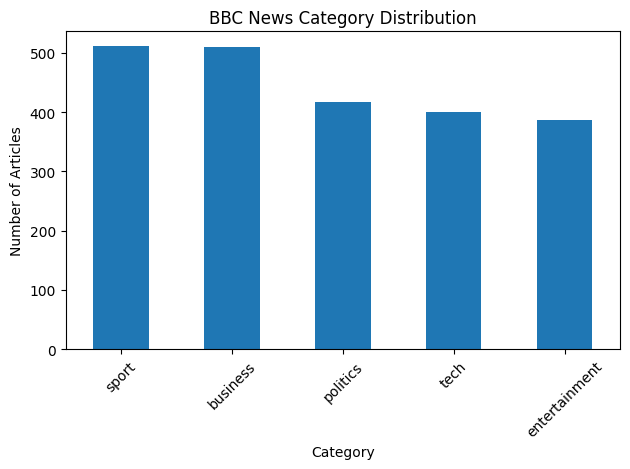

Average text length: 2232.793258426966
Min text length: 471
Max text length: 25454


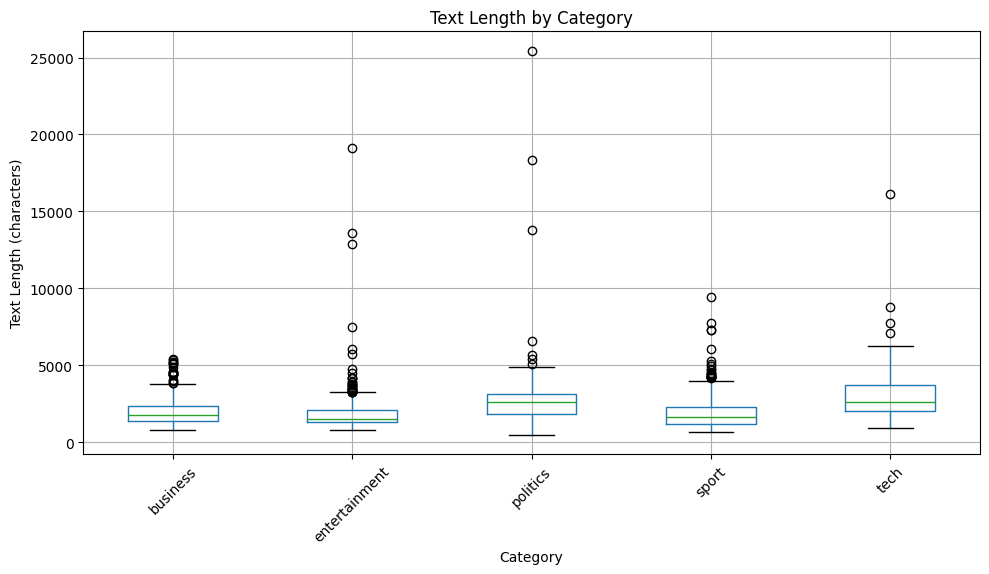

Training set size: 1334
Validation set size: 334
Test set size: 557

Category distribution in training set:
category
business         306
sport            306
politics         250
tech             241
entertainment    231
Name: count, dtype: int64

Category distribution in validation set:
category
sport            77
business         76
politics         63
tech             60
entertainment    58
Name: count, dtype: int64

Category distribution in test set:
category
business         128
sport            128
politics         104
tech             100
entertainment     97
Name: count, dtype: int64


In [11]:
# Explore the first 10 rows
df.head(10) # None

# Basic info and describe
df.describe() # None 
df.info() # None

# Category distribution
category_counts = df['category'].value_counts() # None
category_counts

# Visualize category distribution
category_counts.plot(kind='bar')
plt.xlabel('Category')
plt.ylabel('Number of Articles')
plt.title('BBC News Category Distribution')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
# None

# Text length analysis
df['text_length'] = df['content'].str.len()
print(f"Average text length: {df['text_length'].mean()}")
print(f"Min text length: {df['text_length'].min()}")
print(f"Max text length: {df['text_length'].max()}")

# Visualize text length by category
df.boxplot(column='text_length', by='category', figsize=(10, 6))
plt.title('Text Length by Category')
plt.suptitle('')  # removes the automatic extra title
plt.xlabel('Category')
plt.ylabel('Text Length (characters)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Check for missing values
df.isna().sum() #None

# Map category labels to integers for classification
categories = list(df['category'].unique())
category_mapping = {category: i for i, category in enumerate(categories)}
df['label'] = df['category'].map(category_mapping)

# Rename content column to text
df.rename(columns={'content': 'text'}, inplace=True)

# Split into train, validation, and test sets, make sure to stratify based on category, keep features and target together for now
# First, create train+validation and test sets
train_val_df, test_df = train_test_split(
    df, 
    test_size=0.25,          # 25 % for the final test set  
    stratify=df['category'], # keep category proportions
    random_state=42
)

#None
# Then split train+validation into separate train and validation sets
train_df, val_df = train_test_split(
    train_val_df,
    test_size=0.2,                    # 20 % of the train_val data becomes validation
    stratify= train_val_df['category'], # still keep category balance
    random_state=42
)

# None

print(f"Training set size: {len(train_df)}")
print(f"Validation set size: {len(val_df)}")
print(f"Test set size: {len(test_df)}")

# Ensure categories are distributed properly across splits
print("\nCategory distribution in training set:")
print(train_df['category'].value_counts())
print("\nCategory distribution in validation set:")
print(val_df['category'].value_counts())
print("\nCategory distribution in test set:")
print(test_df['category'].value_counts())

## Part 3: TensorFlow Approach
Implement BERT with TensorFlow and TensorFlow Hub
- Import required libraries
- Select and load a BERT model
- Create datasets
 - Build model architecture
 - Fine-tune the model
 - Evaluate performance
 - Create visuals for train and validation data metrics across epochs


In [15]:
# Make sure to set legacy Keras to work with TF Hub BERT before you import
os.environ['TF_USE_LEGACY_KERAS']= '1'

# Import TensorFlow-specific libraries
import tensorflow as tf
import tensorflow_hub as hub
import tensorflow_text as text

# Select and load BERT model
bert_model_name = 'small_bert/bert_en_uncased_L-4_H-512_A-8'

map_name_to_handle = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/small_bert/bert_en_uncased_L-4_H-512_A-8/1'
}

map_model_to_preprocess = {
    'small_bert/bert_en_uncased_L-4_H-512_A-8': 'https://tfhub.dev/tensorflow/bert_en_uncased_preprocess/3'
}

tfhub_handle_encoder = map_name_to_handle[bert_model_name]
tfhub_handle_preprocess = map_model_to_preprocess[bert_model_name]

# Create TensorFlow datasets
def create_tf_dataset(texts, labels, batch_size=32, shuffle=True):
    dataset = tf.data.Dataset.from_tensor_slices((texts,labels))
    if shuffle:
        dataset = dataset.shuffle(len(texts))
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)
    return dataset
    #None

# Convert pandas DataFrames to TensorFlow datasets
train_dataset = create_tf_dataset(train_df['text'], train_df['label'] ) # None
val_dataset = create_tf_dataset( val_df['text'], val_df['label'] ) # None
# Make sure to not shuffle for test data
test_dataset = create_tf_dataset( test_df['text'], test_df['label'] )# None

# Build the BERT model
def build_tf_classifier_model():
    # Text input
    text_input= tf.keras.layers.Input(shape=(), dtype=tf.string, name='text')

    # Preprocessing layer
    preprocessing_layer = hub.KerasLayer(tfhub_handle_preprocess, name='preprocessing')
    encoder_inputs = preprocessing_layer(text_input)

    # BERT encoder - set trainable=True for fine-tuning
    encoder = hub.KerasLayer(tfhub_handle_encoder, trainable=True, name='BERT_encoder')
    outputs = encoder(encoder_inputs)

    # Use the pooled output for classification
    net = outputs['pooled_output']

    # Add dropout for regularization
    net = tf.keras.layers.Dropout(0.1)(net)

    # Add classification layer (for 5 categories)
    net = tf.keras.layers.Dense(5, activation='softmax', name='classifier')(net)

    # Create model
    model = tf.keras.Model(text_input, net)
    return model

# Create model
tf_classifier_model = build_tf_classifier_model()
tf_classifier_model.summary()

# Compile the model
# Using sparse categorical crossentropy since our labels are integers
loss = tf.keras.losses.SparseCategoricalCrossentropy() # None
# Select accuracy as metric
metrics = ['accuracy'] # None

# Set up learning rate and optimizer
init_lr = .0005
optimizer = tf.keras.optimizers.legacy.Adam(learning_rate=init_lr) # None

# Compile the model
tf_classifier_model.compile(optimizer=optimizer, loss=loss, metrics=metrics)
# None

# Set up early stopping callback based on validation accuracy
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor='val_accuracy',
    patience=3, 
    restore_best_weights=True
) # None

# Train the model for 5 epochs (not enough epochs most likely but to save on time)
print('Fine-tuning BERT model...')
history = tf_classifier_model.fit(
    train_dataset,
    validation_data=val_dataset, 
    epochs = 5, 
    callbacks=[early_stopping]
) # None

ModuleNotFoundError: No module named 'tensorflow_text'

In [16]:
# Evaluate model on testing data
test_loss, test_accuracy = tf_classifier_model.evaluate(test_dataset)# None
print(f'Test accuracy (TensorFlow): {test_accuracy:.3f}')

NameError: name 'tf_classifier_model' is not defined

## Part 4: Model Analysis and Inference
Analyze model performance on testing data
- Create confusion matrix visualization
- Analyze misclassifications
- Identify strengths and weaknesses

### Tensorflow Model

In [ ]:
# Generate predictions for the test set
test_predictions = None
y_pred = None

# Get true labels from testing data
y_true = [labels.numpy() for _, labels in test_dataset.unbatch()]

# Create and visualize the confusion matrix
cm = None
plt.figure(figsize=(10, 8))
disp = None
disp.plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix for BBC News Classification (TensorFlow)')
plt.grid(False)
plt.show()

# Create classification report
report = None
print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=categories))

# Identify strengths and weaknesses
print("\nModel Strengths and Weaknesses:")

# Calculate per-class metrics (use classification report)
per_class_metrics = {}
None

# Find best and worst performing categories
best_category = None
worst_category = None

print(f"\nStrengths:")
print(f"- Overall accuracy: {report['accuracy']:.4f}")
print(f"- Best performing category: {best_category[0]}")
print(f"\nWeaknesses:")
print(f"- Worst performing category: {worst_category[0]}")

# Visualize per-class performance
plt.figure(figsize=(12, 6))
categories_indices = range(len(categories))
width = 0.25

plt.bar([i - width for i in categories_indices],
        [per_class_metrics[cat]['precision'] for cat in categories],
        width=width, label='Precision')
plt.bar(categories_indices,
        [per_class_metrics[cat]['recall'] for cat in categories],
        width=width, label='Recall')
plt.bar([i + width for i in categories_indices],
        [per_class_metrics[cat]['f1-score'] for cat in categories],
        width=width, label='F1-Score')

plt.xlabel('Category')
plt.ylabel('Score')
plt.title('Performance Metrics by Category')
plt.xticks(categories_indices, categories, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
# Create a function for model inference on new articles
def predict_article_category(text, model=tf_classifier_model):
    """
    Predict the category of a news article using the fine-tuned model.

    Args:
        text (str): The text of the news article
        model: The fine-tuned TensorFlow model

    Returns:
        dict: Prediction results including category and confidence scores
    """
    # Make prediction
    prediction = None

    # Get the predicted category and confidence
    predicted_class_id = None
    predicted_category = categories[predicted_class_id]
    confidence = float(prediction[predicted_class_id])

    # Get confidence for all categories
    category_confidences = {categories[i]: float(prediction[i]) for i in range(len(categories))}

    # Sort categories by confidence (descending)
    sorted_categories = sorted(category_confidences.items(), key=lambda x: x[1], reverse=True)

    return {
        'text': text[:100] + '...' if len(text) > 100 else text,
        'predicted_category': predicted_category,
        'confidence': confidence,
        'all_confidences': sorted_categories
    }

# Test the inference function with example articles
sample_articles = [
    "The tech giant announced the release of their new smartphone that features advanced AI capabilities and improved battery life. The product will be available in stores next month.",
    "The football team secured their victory in the final minutes with a spectacular goal. The win puts them at the top of the league table.",
    "Stock markets plummeted following the central bank's announcement of interest rate increases. Investors are concerned about the impact on economic growth.",
    "The new film starring the award-winning actress has received critical acclaim at the international film festival. Critics praised the innovative cinematography.",
    "The government announced new policies regarding digital privacy and data protection. Opposition parties have criticized the measures as inadequate."
]

print("\nTesting inference on sample articles:")
for i, article in enumerate(sample_articles):
    result = predict_article_category(article)
    print(f"\nSample {i+1}:")
    print(f"Text: {result['text']}")
    print(f"Predicted category: {result['predicted_category']} (confidence: {result['confidence']:.4f})")
    print("All category confidences:")
    for category, conf in result['all_confidences']:
        print(f"  - {category}: {conf:.4f}")

# Part 5: Conclusion and Discussion
Summarize your findings
- What was the final accuracy and other metrics?
- What categories were easiest/hardest to classify?
- What challenges did you encounter?
- How might you improve the model further?
